In [1]:
# Modules gotten from Lecture 6 regarding PINNs
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


# Exercise X14.04

This exercise will develop a PINN strategy to discover the solution of a parametrised system of ODEs. The system which is analysed is the four tank system, which is nonlinear. The system is described as:

In [2]:
def four_tank_system(t, x, u, p):
    """Return dx/dt for the four-tank system.

    x: tank masses [g], shape (4,)
    u: pump flow rates [cm^3/s], shape (2,)
    p: parameters, shape (12,)
    """
    x = np.asarray(x, dtype=float).reshape(4)
    u = np.asarray(u, dtype=float).reshape(2)
    p = np.asarray(p, dtype=float).reshape(12)

    # Unpack parameters
    a = p[0:4]       # Pipe cross-sectional areas [cm^2]
    A = p[4:8]       # Tank cross-sectional areas [cm^2]
    gamma = p[8:10]  # Valve positions [-]
    g = p[10]        # Acceleration of gravity [cm/s^2]
    rho = p[11]      # Water density [g/cm^3]

    # Inflows
    qin = np.array([
        gamma[0] * u[0],
        gamma[1] * u[1],
        (1 - gamma[1]) * u[1],
        (1 - gamma[0]) * u[0],
    ])

    # Outflows
    x[x < 0] = 0 # Masses can't be negative
    h = x / (rho * A)
    qout = a * np.sqrt(2 * g * h)

    # Mass balances
    return rho * np.array([
        qin[0] + qout[2] - qout[0],
        qin[1] + qout[3] - qout[1],
        qin[2] - qout[2],
        qin[3] - qout[3],
    ])

The four tank system is a set of simple, nonlinear ODEs, which describe the flow of water through four tanks. It is assumed that the tank and pipe areas are known for all four tanks. Furthermore, the density of the liquid is also assumed to be known. The parameters that the PINN should use are the inlet flows, F1 and F2. These are assumed to vary between 0 and 200 cm3/s.

The valve openings, gamma1 and gamma2, are assumed constant at 0.6 and 0.7 repectively.

In [4]:
# Constant parameters
a1 = 1.2272  # [cm^2] Area of outlet pipe 1
a2 = 1.2272  # [cm^2] Area of outlet pipe 2
a3 = 1.2272  # [cm^2] Area of outlet pipe 3
a4 = 1.2272  # [cm^2] Area of outlet pipe 4

A1 = 380.1327  # [cm^2] Cross-sectional area of tank 1
A2 = 380.1327  # [cm^2] Cross-sectional area of tank 2
A3 = 380.1327  # [cm^2] Cross-sectional area of tank 3
A4 = 380.1327  # [cm^2] Cross-sectional area of tank 4

ap = np.array([a1, a2, a3, a4])  # [cm^2] Pipe cross-sectional areas
At = np.array([A1, A2, A3, A4])  # [cm^2] Tank cross-sectional areas

gamma1 = 0.6  # Flow distribution constant for valve 1
gamma2 = 0.7  # Flow distribution constant for valve 2

gam = np.array([gamma1, gamma2])

g = 981   # [cm/s^2] Acceleration of gravity
rho = 1.00  # [g/cm^3] Density of water

rhoA = rho*At

# Parameter vector, in the order expected by four_tank_system
p = np.array([a1, a2, a3, a4, A1, A2, A3, A4, gamma1, gamma2, g, rho])

To generate training data, the system is solved using the ode solver "scipy.integrate.solve_ivp". Multiple scenarios are simulated, to train the PINN on different conditions. The PINN takes time and inlet flows as inputs and will output the states, masses in all four tanks. To simplify the problem, it is therefore assumed that the initial condition is always that the tanks are empty. One could make the PINN more advanced, and also give the initial condition as inlet.

To generate training data, 20 different scenarios are tested, where the inlet flowrate of F1 and F2 are randomly chosen to be between 50 and 150 cm^3 / s. The system is solved for each of these conditions for 10 min. A sampling time of 1 s is used for collocation points. Measurements are assumed to be taken every 30 s, and it is assumed that there are no noise on the measurements.

After each scenario is simulated, the data is processed, to fit the PINN. During construction of the PINN, it was seen that the data was not very well scaled, so in order to mitigate scaling problems, all training data was normalized to be between 0 and 1. All the data are also converted to tensors, to fit with the tensor package.

Copilot has been used to structure the creation of the 10 scenarios, normalization and to convert the numpy arrays to tensors.

In [ ]:
# Simulation parameters
x0 = np.array([0, 0, 0, 0])
u0 = np.ones(2) * 100
dt = 1 # s
T = 10*60 # s
tspan = np.arange(0, T + dt, dt) # s

rng = np.random.default_rng(42)
n_scenarios = 20

u_scenarios = np.vstack((
    u0,
    rng.uniform(50.0, 150.0, size=(n_scenarios - 1, 2)),
)) # 20 scenarios with constant u's
x0 = np.zeros(4) # Always start from zero

measurement_idx = np.arange(0, len(tspan), 30) # Measurement indexes
trajectories = []

for u_i in u_scenarios:
    sol_i = solve_ivp(
        four_tank_system,
        (tspan[0], tspan[-1]),
        x0,
        t_eval=tspan,
        args=(u_i, p),
    )
    if not sol_i.success:
        raise RuntimeError(sol_i.message)

    trajectories.append(sol_i.y)

# Normalize against the whole training set
m_max_np = np.maximum(np.max(np.stack(trajectories), axis=(0, 2)), 1e-6)
u_scale_np = np.maximum(np.max(u_scenarios, axis=0), 1e-6)
t_scale = float(tspan[-1])

m_max_t = torch.as_tensor(m_max_np, dtype=torch.float32, device=device)
u_scale_t = torch.as_tensor(u_scale_np, dtype=torch.float32, device=device)

# -------- TRAINING DATA --------

# Data points
t_meas = tspan[measurement_idx]
# Repeat it once per scenario, matching the scenario-by-scenario order
tau_train = np.tile(t_meas / t_scale, n_scenarios).reshape(-1, 1)
m_data_train = np.concatenate([m[:, measurement_idx].T for m in trajectories], axis=0)
u_data_train = np.repeat(u_scenarios, len(measurement_idx), axis=0)

t_d = torch.as_tensor(tau_train, dtype=torch.float32, device=device)
m_d = torch.as_tensor(m_data_train, dtype=torch.float32, device=device) / m_max_t
u_d = torch.as_tensor(u_data_train, dtype=torch.float32, device=device) / u_scale_t

# Collocation points: every 1 s, for every inlet-flow scenario.
tau_collocation = np.tile(tspan / t_scale, n_scenarios).reshape(-1, 1)
u_scaled_collocation = np.repeat(u_scenarios, len(tspan), axis=0)

t_f = torch.as_tensor(tau_collocation, dtype=torch.float32, device=device).requires_grad_(True)
u_f = torch.as_tensor(u_scaled_collocation, dtype=torch.float32, device=device) / u_scale_t

# Convert constants to tensor
p_t = torch.as_tensor(p, dtype=torch.float32, device=device)


The 20 training scenarios are now plotted. Copilot has been used to create the plotting code.

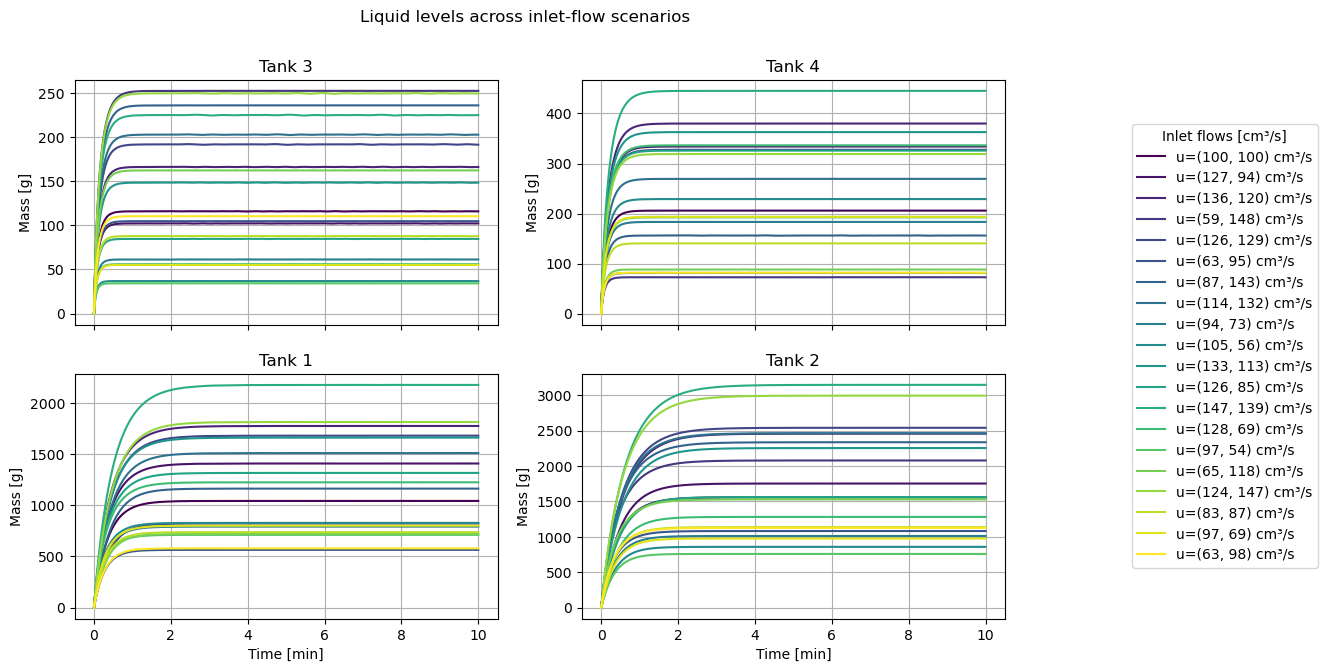

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
axes = axes.ravel()
tank_order = [2, 3, 0, 1]

colors = plt.cm.viridis(np.linspace(0, 1, n_scenarios))

for scenario, (heights, u_i, color) in enumerate(
    zip(trajectories, u_scenarios, colors)
):
    label = f"u=({u_i[0]:.0f}, {u_i[1]:.0f}) cm³/s"

    for ax, i in zip(axes, tank_order):
        ax.plot(
            tspan / 60,
            heights[i],
            color=color,
            label=label,
        )

for ax, i in zip(axes, tank_order):
    ax.set_title(f"Tank {i + 1}")
    ax.set_ylabel("Mass [g]")
    ax.grid(True)

for ax in axes[2:]:
    ax.set_xlabel("Time [min]")

# Use one shared legend rather than repeating it in every panel.
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    title="Inlet flows [cm³/s]",
    loc="center left",
    bbox_to_anchor=(1.0, 0.5),
)

fig.suptitle("Liquid levels across inlet-flow scenarios")
plt.show()

The plots show how the mass in the four tanks change with time. The different inlet conditions determines how full each tank becomes. They all reach steady state well within the given time frame.

The residuals are calculated in the collacation points. In order to do so, the differential equation must be defined in torch variables:

In [ ]:
def four_tank_rhs_torch(x, u, p): 
    # Unpack parameters
    a = p[0:4]       # Pipe cross-sectional areas [cm^2]
    A = p[4:8]       # Tank cross-sectional areas [cm^2]
    gamma = p[8:10]  # Valve positions [-]
    g = p[10]        # Acceleration of gravity [cm/s^2]
    rho = p[11]      # Water density [g/cm^3]

    # Inflows
    qin = torch.stack([
        gamma[0] * u[:, 0],
        gamma[1] * u[:, 1],
        (1 - gamma[1]) * u[:, 1],
        (1 - gamma[0]) * u[:, 0],
    ], dim=1)

    # Outflows
    # make differentiable (this is more robust that forcing x to be positive)
    h = torch.clamp(x / (rho * A), min=1e-6) 
    qout = a * torch.sqrt(2 * g * h)

    # Mass balances
    return rho * torch.stack([
        qin[:, 0] + qout[:, 2] - qout[:, 0],
        qin[:, 1] + qout[:, 3] - qout[:, 1],
        qin[:, 2] - qout[:, 2],
        qin[:, 3] - qout[:, 3],
    ], dim=1)

The residuals are computed using code from the Lecture slide, which was slightly modified by Claude to update some functions. In order to evaluate the physical error of the network, mass and time must be scaled back to "physical" values, before they are inserted into the differential equation. The output of the equation is then normalized, to calculate the scaled residual.

In [ ]:
def compute_residuals(tau, u_s, p):
    z = net(tau, u_s) # NN estimation (scaled mass)
    z_tau = torch.cat([
        torch.autograd.grad(
            z[:, i:i+1],
            tau,
            grad_outputs=torch.ones_like(z[:, i:i+1]),
            create_graph=True,
        )[0]
        for i in range(4)
    ], dim=1)    # dz/dtau (NN diff scaled)

    u_norm = u_s * u_scale_t    # physical inlwet flows
    z_norm = z * m_max_t        # physical mass

    x_t_norm = four_tank_rhs_torch(z_norm, u_norm, p)  # [g/s] (physical values)

    x_t = t_scale * x_t_norm / m_max_t      # scaled rate of change

    # dz/dtau = x_t   -> residual
    return z_tau - x_t

Now the PINN is defined using the same definition as in the Lecture slides.
Claude has been used to modify the PINN class slightly, as some of the functions in the lecture slides where outdated. Furthermore, now three inputs are used, as not only time, but also the two inlet flows are used for estimation. THe PINN outputs four nodes, which are the masses of each tank.

In [ ]:
# Parameters
n_neurons = 50 # hidden nodes in each layer
lr = 0.01 # learning rate, optimizer
criterion = nn.MSELoss()
n_epochs = 5000 # total epoch to train
n_input = 3
n_output = 4

class PINN(nn.Module):
    def __init__(self):
        super().__init__()
        self.body = nn.Sequential(
        nn.Linear(n_input, n_neurons), nn.Tanh(), # Inputs are time and inlet flows = 3
        nn.Linear(n_neurons, n_neurons),nn.Tanh(),
        nn.Linear(n_neurons, n_neurons),nn.Tanh(),
        nn.Linear(n_neurons, n_neurons),nn.Tanh(),
        nn.Linear(n_neurons, n_output), # Four states to output
        )
    
    # forward method
    def forward(self, t, u):
        # 1 time + 2 flows
        features = torch.cat((t, u), dim=1)
        return t * self.body(features)


net = PINN().to(device)

The training algorithm from the Lecture slides is modified to fit traning on each scenario.
Three different losses are calculated. The "original" data loss, obtained directly from the PINN's estimations and the measured data points. The boundary/initial condition loss, which is evaluated at t=0, where it is assumed that each tank is empty in all training cases. This should in principle also be evaluated by the data loss, as the first data point is the initial conditions, however for clarity, it is chosen to include the IC loss. Lastly the physical loss, obtained at each collocation point is calculated from the residual function defined above.
Weighting parameters are included, but after scaling all variables, these were actually tuned to 1, so each loss is weighted equally.

In [ ]:
optimizer = optim.Adam(net.parameters(), lr=0.01)

lambda_f = 1
lambda_d = 1
n_phys = 3000

A_t = p_t[4:8]
rho_t = p_t[11]

# Use the first measurement as the initial condition.
t0_t = t_d[0:1]
u0_t = u_d[0:1]
x0_t = m_d[0:1]

for epoch in range(n_epochs):    
    optimizer.zero_grad()

    # Data loss (L_d)
    x_NN = net(t_d, u_d)
    loss_data = criterion(x_NN, m_d)

    # Boundary/IC loss (L_IC)
    x0_NN = net(t0_t, u0_t)
    loss_IC = criterion(x0_NN, x0_t)

    # Physics loss (collocation loss) (L_p)
    residual = compute_residuals(t_f, u_f, p_t)
    loss_physics = criterion(residual, torch.zeros_like(residual))

    # Total PINN loss (L)
    loss = lambda_d * loss_data + loss_IC + lambda_f * loss_physics

    # Update internal PINN weights
    loss.backward()
    optimizer.step()

    # Print each loss every 500 epoch, to evaluate if any of the losses overrule the other
    # This was used to tune the individual loss weigths
    if (epoch + 1) % 500 == 0:
        print(
            f"Epoch {epoch + 1}/{n_epochs} | "
            f"data: {loss_data.item():.6e} | "
            f"IC: {loss_IC.item():.6e} | "
            f"physics: {loss_physics.item():.6e} | "
            f"total: {loss.item():.6e}"
        )


Epoch 500/5000 | data: 1.761663e-03 | IC: 0.000000e+00 | physics: 2.099304e+01 | total: 2.099481e+01
Epoch 1000/5000 | data: 5.380802e-04 | IC: 0.000000e+00 | physics: 1.233698e+01 | total: 1.233752e+01
Epoch 1500/5000 | data: 1.481887e-03 | IC: 0.000000e+00 | physics: 1.052296e+01 | total: 1.052444e+01
Epoch 2000/5000 | data: 1.597473e-04 | IC: 0.000000e+00 | physics: 7.105164e+00 | total: 7.105324e+00
Epoch 2500/5000 | data: 1.312443e-04 | IC: 0.000000e+00 | physics: 6.014495e+00 | total: 6.014627e+00
Epoch 3000/5000 | data: 7.232537e-04 | IC: 0.000000e+00 | physics: 6.906986e+00 | total: 6.907710e+00
Epoch 3500/5000 | data: 9.923182e-05 | IC: 0.000000e+00 | physics: 4.468493e+00 | total: 4.468592e+00
Epoch 4000/5000 | data: 8.131240e-05 | IC: 0.000000e+00 | physics: 3.929703e+00 | total: 3.929784e+00
Epoch 4500/5000 | data: 5.122611e-04 | IC: 0.000000e+00 | physics: 4.597280e+00 | total: 4.597792e+00
Epoch 5000/5000 | data: 6.881772e-05 | IC: 0.000000e+00 | physics: 3.191236e+00 | t

When training the PINN no validation set has been used. This was purely to simplify the process. A more robust and accurate PINN could probably be developed, if the hyperparameters were tuned using a validation set.

To evaluate if the PINN has been trained sufficiently, and if it is accurately able to fit to the traning data, the PINN estimations are plotted against the traning data set, for each collocation point.

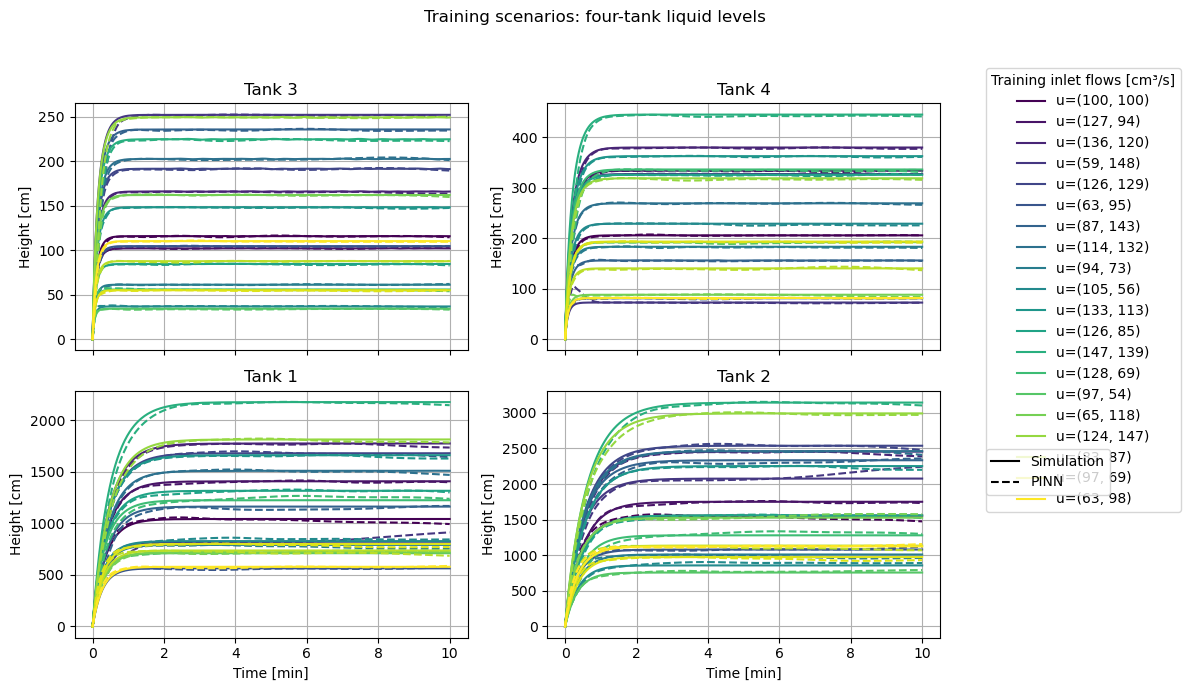

In [ ]:
# Predict each training scenario with its own inlet-flow condition.

tau_plot = torch.as_tensor(
    tspan / t_scale, dtype=torch.float32, device=device
).reshape(-1, 1) # scaled time

A_t = p_t[4:8]
rho_t = p_t[11]

net.eval() # Switch to evaluation mode (no training)
x_nn_train = []
with torch.no_grad():
    for u_i in u_scenarios:
        u_input = torch.as_tensor(
            u_i, dtype=torch.float32, device=device
        ).reshape(1, 2).expand(len(tspan), -1) / u_scale_t # scaled inlet flows

        x_pred_scale = net(tau_plot, u_input)
        # Scale prediction back to physical masses
        x_pred = x_pred_scale * m_max_t
        x_nn_train.append(x_pred.cpu().numpy().T)

fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
axes = axes.ravel()
tank_order = [2, 3, 0, 1]
time_min = tspan / 60
sample_time_min = tspan[measurement_idx] / 60

for ax, tank_i in zip(axes, tank_order):
    for s in range(n_scenarios):
        color = colors[s]
        u_i = u_scenarios[s]
        label = f"u=({u_i[0]:.0f}, {u_i[1]:.0f})"

        # Simulated reference trajectory.
        ax.plot(
            time_min,
            trajectories[s][tank_i],
            color=color,
            label=label if tank_i == tank_order[0] else None,
        )

        # PINN prediction for this scenario.
        ax.plot(
            time_min,
            x_nn_train[s][tank_i],
            "--",
            color=color,
        )


    ax.set_title(f"Tank {tank_i + 1}")
    ax.set_ylabel("Height [cm]")
    ax.grid(True)

for ax in axes[2:]:
    ax.set_xlabel("Time [min]")

# Scenario colors and line styles are explained separately.
scenario_handles, scenario_labels = axes[0].get_legend_handles_labels()
fig.legend(
    scenario_handles,
    scenario_labels,
    title="Training inlet flows [cm³/s]",
    loc="center left",
    bbox_to_anchor=(0.82, 0.58),
)

style_handles = [
    Line2D([0], [0], color="black", linestyle="-", label="Simulation"),
    Line2D([0], [0], color="black", linestyle="--", label="PINN"),
]
fig.legend(
    handles=style_handles,
    loc="center left",
    bbox_to_anchor=(0.82, 0.32),
)

fig.suptitle("Training scenarios: four-tank liquid levels")
fig.tight_layout(rect=[0, 0, 0.8, 0.94])
plt.show()


It is seen that the PINN can reasonably fit to the training data. It seems that the estimation for tank 3 and 4 are more precise than for tank 1 and 2. In both 1 and 2 it seems to struggle with fitting the steady state solution. It also shows one trajectory for tank 4, where the height is initially overestimated. However the PINN is able to correct for this. Even though the PINN shows some deviation near the end of the traning window for tank 1 and 2, it is estimated to fit the training data well enough to proceed to testing.

The PINN is now tested on unseen data, with new values of inlet flowrates. Three scenarios are tested, one indside the training range, one below and one above. The three true trajectories are found by solving the IVP and the PINN estimation are found for all three.

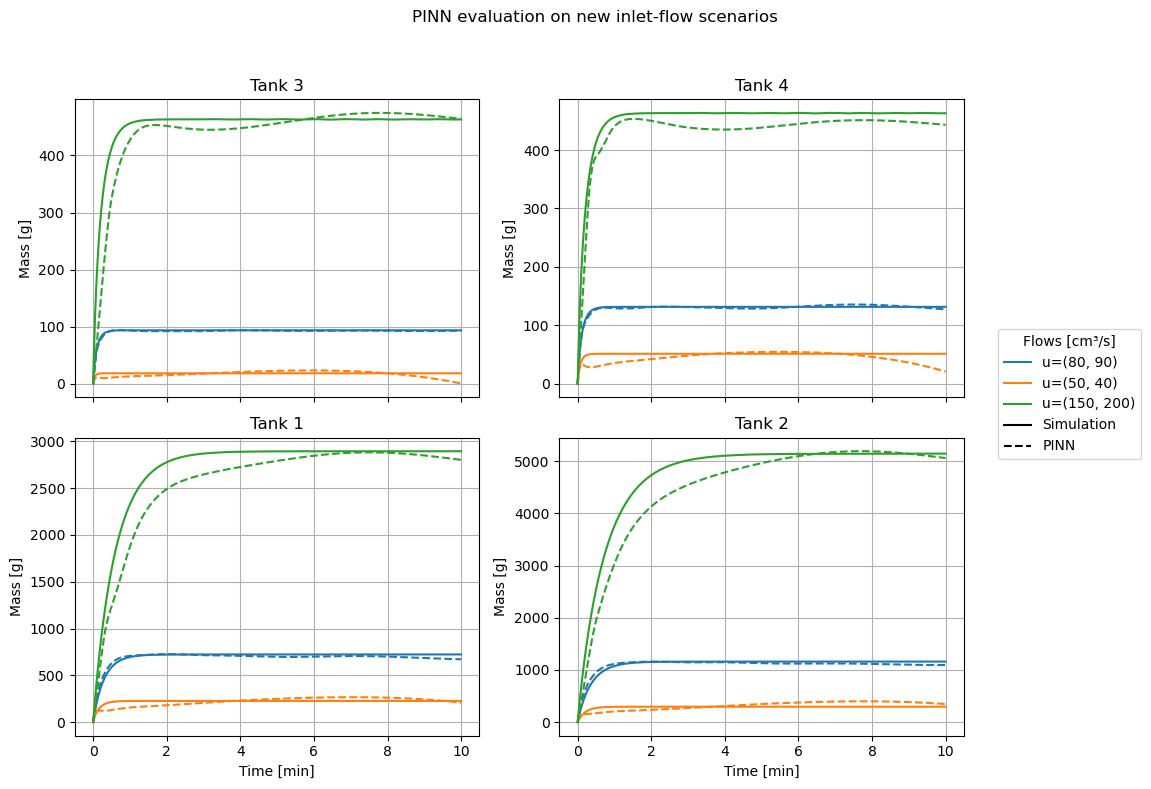

u=(np.float64(80.0), np.float64(90.0)): Mass MSE = 644.428989 g
u=(np.float64(50.0), np.float64(40.0)): Mass MSE = 1749.185796 g
u=(np.float64(150.0), np.float64(200.0)): Mass MSE = 43192.938263 g


In [ ]:
# New evaluation flows: one inside the training range, two outside.
u_test_scenarios = np.array([
    [80.0, 90.0],
    [50.0, 40.0],
    [150.0, 200.0],
])

tau_test_plot = torch.as_tensor(
    tspan / t_scale, dtype=torch.float32, device=device
).reshape(-1, 1) # scaled time

test_trajectories = []
test_predictions = []

# Predict each training scenario with its own inlet-flow condition.
net.eval()
with torch.no_grad():
    for u_i in u_test_scenarios:
        # True trajectory from solving the ODE
        sol_test = solve_ivp(
            four_tank_system,
            (tspan[0], tspan[-1]),
            x0,
            t_eval=tspan,
            args=(u_i, p),
        )

        m_reference = sol_test.y
        test_trajectories.append(m_reference)

        # PINN estimated trajectory
        u_i_norm = (torch.as_tensor(u_i, dtype=torch.float32, device=device) / u_scale_t) # scaled inlet flow
        u_input = u_i_norm.reshape(1, 2).expand(len(tspan), -1)

        m_pred_norm = net(tau_test_plot, u_input)
        # scale mass back to physical values
        m_prediction = (m_pred_norm * m_max_t).cpu().numpy().T
        test_predictions.append(m_prediction)

# Compare simulation and PINN predictions for all four tanks.
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
axes = axes.ravel()
tank_order = [2, 3, 0, 1]
colors = plt.cm.tab10(np.arange(len(u_test_scenarios)))

for ax, tank_i in zip(axes, tank_order):
    for scenario_i, u_i in enumerate(u_test_scenarios):
        label = f"u=({u_i[0]:.0f}, {u_i[1]:.0f}) cm³/s"
        color = colors[scenario_i]

        ax.plot(
            tspan / 60,
            test_trajectories[scenario_i][tank_i],
            color=color,
            label=label,
        )
        ax.plot(
            tspan / 60,
            test_predictions[scenario_i][tank_i],
            "--",
            color=color,
        )

    ax.set_title(f"Tank {tank_i + 1}")
    ax.set_ylabel("Mass [g]")
    ax.grid(True)

for ax in axes[2:]:
    ax.set_xlabel("Time [min]")

scenario_handles = [
    Line2D([0], [0], color=colors[i], label=f"u=({u[0]:.0f}, {u[1]:.0f})")
    for i, u in enumerate(u_test_scenarios)
]
style_handles = [
    Line2D([0], [0], color="black", linestyle="-", label="Simulation"),
    Line2D([0], [0], color="black", linestyle="--", label="PINN"),
]

fig.legend(
    handles=scenario_handles + style_handles,
    loc="center left",
    bbox_to_anchor=(0.83, 0.5),
    title="Flows [cm³/s]",
)
fig.suptitle("PINN evaluation on new inlet-flow scenarios")
fig.tight_layout(rect=[0, 0, 0.82, 0.95])
plt.show()

# Report errors per scenario in physical height units.
for u_i, m_reference, m_prediction in zip(
    u_test_scenarios, test_trajectories, test_predictions
):
    mse_g = np.mean((m_prediction - m_reference) ** 2)
    print(f"u={tuple(u_i)}: Mass MSE = {mse_g:.6f} g")

The plots show that the PINN is nicely able to follow the trajectory for the scenario which falls inside the traning range. However, the two scenarios outisde the training range are less accurate. This is generally expected for neural networks, as they often have difficulty with extrapolating. However, one of the advantages of PINNs, is that they should show better extrapolating performances, as they include the physical understanding of the system, in their traning/fitting. However, it is seen here, that the PINN still can struggle with extrapolation. This can be becuase the physics of the system may also change when the parameters change. It is seen that the PINN underestimates the rate of change for the flow rates outside the trained parameter bounds. It cpuld perhaps find a steady solution for the higher flow rates, if the simulation had run for a longer time, however for the lower inlet rates, it seems to go towards a non-physical solution with negative masses (seen in tank 3). The PINN should perhaps be trained on data with no inlet flows, to understand the physics of empty tanks.

Furthermore, it has not been tested, how the PINN would react to changing inlet flows during the time period, or how it estimates outside the trained time period. Many additional tests could be performed to outline where the PINN struggles and where it is able to accurately estimate the system.

In conclusion a parameterised PINN was developed and it shows the ability to follow trajecotries both inside and outside its trained parameter set. Many more test could be done, and the PINN could definently be stregthen by e.g. including a validation set structure or diversifying the training data. This is a simple example, showing that PINNs can be used for solving differential equations.